In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
data = pd.read_csv("../data/student_mental_health.csv")

print(data.head())
print("---------------les dimensions----------------")
print(data.shape)

print("---------------les colonnes----------------")
print(data.columns)
print("---------------les types----------------")
print(data.dtypes)
print("---------------info----------------")
data.info()


data_original = data.copy()

  Student_ID  Age  Gender  Year_of_Study  Sleep_Hours  Study_Hours_Per_Week  \
0    STU0001   22    Male              3          6.6                  17.6   
1    STU0002   21    Male              4          5.6                  22.4   
2    STU0003   22    Male              5          7.1                  28.1   
3    STU0004   24    Male              1          4.5                  14.8   
4    STU0005   20  Female              1          6.7                  17.2   

    GPA  Social_Media_Hours  Screen_Time_Hours Physical_Activity  \
0  2.91                 6.9                7.5          Moderate   
1  2.92                 7.6               11.5               Low   
2  2.68                 6.5                8.9               Low   
3  2.23                 5.5                7.6              High   
4  2.69                 4.3                7.0          Moderate   

   Financial_Stress  Family_Support  Attendance_Rate Part_Time_Job  \
0               8.5             4.0           

In [4]:
# print(data.isna().sum())
print("---------------- pourcentage de valeurs manquantes ----------------")
print((data.isna().sum()/len(data))*100)
print("---------------- les doublons ----------------")
print(data.duplicated().sum())


---------------- pourcentage de valeurs manquantes ----------------
Student_ID                        0.00
Age                               0.00
Gender                            0.00
Year_of_Study                     0.00
Sleep_Hours                       3.10
Study_Hours_Per_Week              0.00
GPA                               1.90
Social_Media_Hours                2.90
Screen_Time_Hours                 0.00
Physical_Activity                 0.00
Financial_Stress                  4.55
Family_Support                    2.70
Attendance_Rate                   2.35
Part_Time_Job                     0.00
Diet_Quality                      3.45
Previous_Mental_Health_History    0.00
Mental_Health_Risk                0.00
dtype: float64
---------------- les doublons ----------------
0


In [5]:
numeric_columns = data.select_dtypes(include="number").columns
nu = ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA','Attendance_Rate']
for col in nu:
    # print(data[col]<=0)
    if (data[col]<=0).any():
        print(f"-------- {col}---------")
        print(data[col])

vérifier si toutes les valeurs ont des valeurs supérieures à 0

In [6]:
# l'incoherence
age = data[
    data["Age"] < (17 + data["Year_of_Study"])
] 

print(age[["Age", "Year_of_Study"]].to_string())
print("*"*30)
print(len(age[["Age", "Year_of_Study"]]))

      Age  Year_of_Study
5      20              4
10     20              5
11     20              5
13     17              2
14     17              4
23     18              3
26     18              4
30     20              5
32     21              5
35     18              4
37     17              5
38     18              2
44     18              3
49     17              1
56     19              4
57     20              4
60     20              5
69     20              4
74     17              1
76     21              5
79     17              3
84     19              4
85     20              4
92     19              5
94     20              4
100    18              4
103    19              3
110    17              1
117    18              3
121    19              3
123    18              4
127    20              4
129    20              5
130    18              3
134    19              5
136    19              4
142    17              2
146    18              2
147    18              4


In [7]:
screen_check =data[(data["Sleep_Hours"] + data["Screen_Time_Hours"] > 24) | (data["Social_Media_Hours"] > data["Screen_Time_Hours"])]

screen_check[["Student_ID","Sleep_Hours","Screen_Time_Hours","Social_Media_Hours"]]

print(screen_check[["Student_ID","Social_Media_Hours","Screen_Time_Hours"]])

     Student_ID  Social_Media_Hours  Screen_Time_Hours
78      STU0079                 5.0                4.9
168     STU0169                 5.6                5.3
209     STU0210                 7.5                7.3
278     STU0279                 6.0                5.1
382     STU0383                 5.3                4.1
424     STU0425                 5.5                4.4
476     STU0477                 5.5                5.3
505     STU0506                 5.6                5.5
557     STU0558                 4.6                4.4
588     STU0589                 5.7                5.3
628     STU0629                 4.9                4.6
641     STU0642                 5.4                4.8
718     STU0719                 6.2                5.9
758     STU0759                 7.1                6.1
784     STU0785                 7.9                6.9
942     STU0943                 5.8                5.7
951     STU0952                 5.4                5.2
956     ST

Le nombre d'heures passées sur les réseaux sociaux ne doit pas dépasser le temps total passé devant les écrans.


In [8]:
print(
    data[data["Social_Media_Hours"] > data["Screen_Time_Hours"]][["Student_ID","Social_Media_Hours","Screen_Time_Hours"]]
)

     Student_ID  Social_Media_Hours  Screen_Time_Hours
78      STU0079                 5.0                4.9
168     STU0169                 5.6                5.3
209     STU0210                 7.5                7.3
278     STU0279                 6.0                5.1
382     STU0383                 5.3                4.1
424     STU0425                 5.5                4.4
476     STU0477                 5.5                5.3
505     STU0506                 5.6                5.5
557     STU0558                 4.6                4.4
588     STU0589                 5.7                5.3
628     STU0629                 4.9                4.6
641     STU0642                 5.4                4.8
718     STU0719                 6.2                5.9
758     STU0759                 7.1                6.1
784     STU0785                 7.9                6.9
942     STU0943                 5.8                5.7
951     STU0952                 5.4                5.2
956     ST

In [9]:
data["Social_Media_Hours"] = np.minimum(
    data["Social_Media_Hours"],
    data["Screen_Time_Hours"]
)

In [10]:
print(
    data[data["Social_Media_Hours"] > data["Screen_Time_Hours"]][["Student_ID","Social_Media_Hours","Screen_Time_Hours"]]
)

Empty DataFrame
Columns: [Student_ID, Social_Media_Hours, Screen_Time_Hours]
Index: []


In [11]:
sleep_hours_per_week = data["Sleep_Hours"] * 7
study_hours_per_week = data["Study_Hours_Per_Week"]
screen_hours_per_week = data["Screen_Time_Hours"] * 7 


total_hours = data[(sleep_hours_per_week + study_hours_per_week + screen_hours_per_week)>168]
print(total_hours)
print(len(total_hours))

     Student_ID  Age Gender  Year_of_Study  Sleep_Hours  Study_Hours_Per_Week  \
650     STU0651   25   Male              2          9.8                  24.6   
1497    STU1498   24   Male              4          8.8                  19.3   
1550    STU1551   21   Male              1          8.4                  20.7   

       GPA  Social_Media_Hours  Screen_Time_Hours Physical_Activity  \
650   2.30                 6.6               11.0          Moderate   
1497  3.13                 7.7               12.7          Moderate   
1550  2.65                 9.2               12.7          Moderate   

      Financial_Stress  Family_Support  Attendance_Rate Part_Time_Job  \
650                NaN             7.3             84.0            No   
1497               NaN             6.7             86.9            No   
1550               8.1             4.6             95.8           Yes   

     Diet_Quality Previous_Mental_Health_History Mental_Health_Risk  
650       Average          

Le total des heures hebdomadaires calculées ne doit pas dépasser 168 heures.

In [12]:
print(data.describe())

               Age  Year_of_Study  Sleep_Hours  Study_Hours_Per_Week  \
count  2000.000000    2000.000000  1938.000000           2000.000000   
mean     21.131500       2.630000     6.758875             19.997900   
std       2.139275       1.316802     1.127072              5.719274   
min      17.000000       1.000000     3.300000              2.400000   
25%      20.000000       1.000000     6.000000             16.000000   
50%      21.000000       2.000000     6.700000             19.800000   
75%      23.000000       4.000000     7.600000             24.000000   
max      29.000000       5.000000    10.000000             38.300000   

               GPA  Social_Media_Hours  Screen_Time_Hours  Financial_Stress  \
count  1962.000000         1942.000000        2000.000000       1909.000000   
mean      2.562503            6.004686           8.548500          5.956260   
std       0.343993            1.156263           1.657571          1.893941   
min       1.500000            2.100

In [13]:
print(data.describe(include="object"))

       Student_ID  Gender Physical_Activity Part_Time_Job Diet_Quality  \
count        2000    2000              2000          2000         1931   
unique       2000       3                 3             2            3   
top       STU0001  Female          Moderate            No      Average   
freq            1     971               906          1289          860   

       Previous_Mental_Health_History Mental_Health_Risk  
count                            2000               2000  
unique                              2                  3  
top                                No               High  
freq                             1408                680  


C:\Users\elgot\AppData\Local\Temp\ipykernel_15916\781630022.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(data.describe(include="object"))


In [14]:
def detect_outliers(data,col):
    Q1=data[col].quantile(0.25)
    Q3=data[col].quantile(0.75)
    IQR=Q3-Q1

    lower = Q1 - (1.5 * IQR)
    upper = Q3 + (1.5 * IQR)

    outliers = data[(data[col]>upper) | (data[col]<lower)]

    print(f"{col} : {len(outliers)} valeur aberrantes")

    return outliers

# numeric_columns = data.select_dtypes(include="number").columns

for col in numeric_columns:
    outliers = detect_outliers(data,col)


print("----------------===============")
# print(detect_outliers(data,"Age")["Age"])
# print(detect_outliers(data,"Age")["Sleep_Hours"])
# print(detect_outliers(data,"Age")["Study_Hours_Per_Week"])
# print(detect_outliers(data,"Age")["GPA"])
# print(detect_outliers(data,"Age")["Social_Media_Hours"])


for col in numeric_columns:
    print(f"---------{col}---------")
    print(detect_outliers(data,col)[col])


Age : 4 valeur aberrantes
Year_of_Study : 0 valeur aberrantes
Sleep_Hours : 2 valeur aberrantes
Study_Hours_Per_Week : 7 valeur aberrantes
GPA : 9 valeur aberrantes
Social_Media_Hours : 19 valeur aberrantes
Screen_Time_Hours : 7 valeur aberrantes
Financial_Stress : 0 valeur aberrantes
Family_Support : 0 valeur aberrantes
Attendance_Rate : 12 valeur aberrantes
----------------===============
---------Age---------
Age : 4 valeur aberrantes
209     29
478     28
1615    28
1957    28
Name: Age, dtype: int64
---------Year_of_Study---------
Year_of_Study : 0 valeur aberrantes
Series([], Name: Year_of_Study, dtype: int64)
---------Sleep_Hours---------
Sleep_Hours : 2 valeur aberrantes
749     3.6
1982    3.3
Name: Sleep_Hours, dtype: float64
---------Study_Hours_Per_Week---------
Study_Hours_Per_Week : 7 valeur aberrantes
340      3.9
453      3.2
519      3.6
716     38.3
866      2.4
937     37.5
1042     2.7
Name: Study_Hours_Per_Week, dtype: float64
---------GPA---------
GPA : 9 valeur a

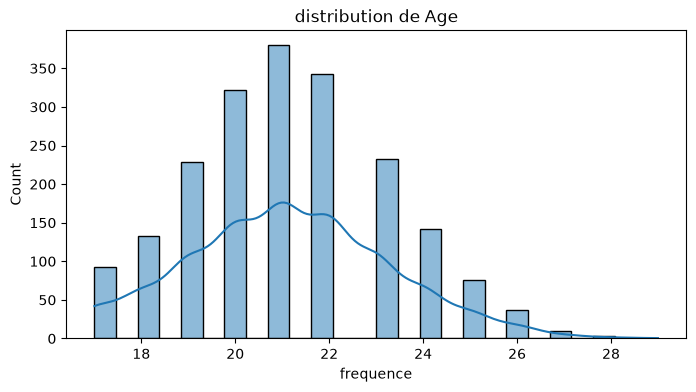

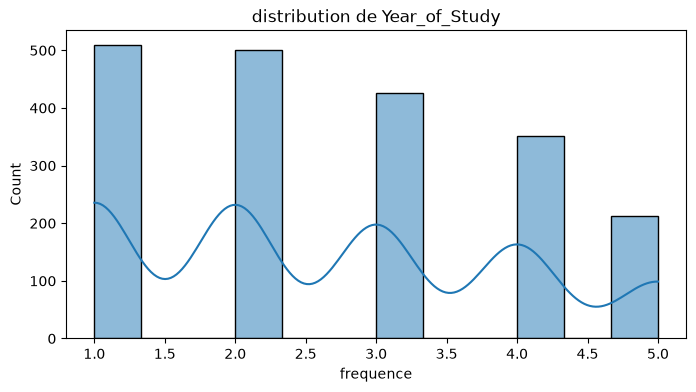

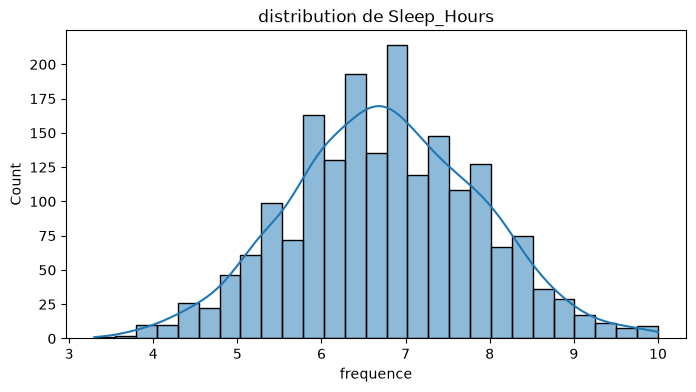

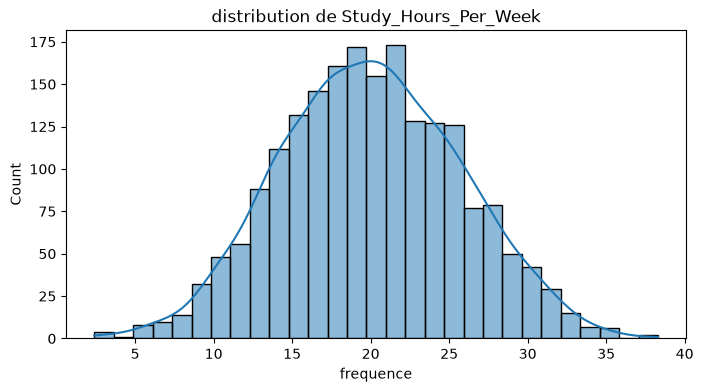

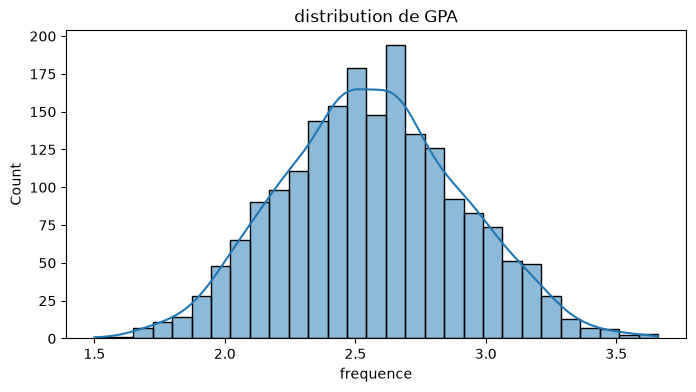

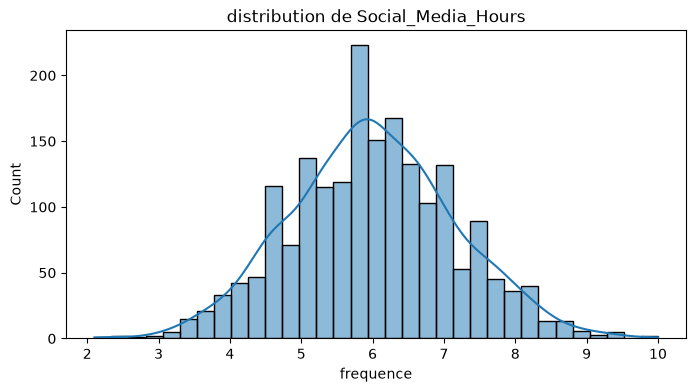

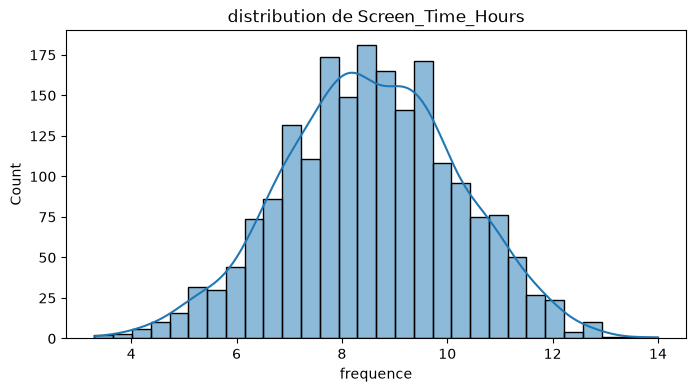

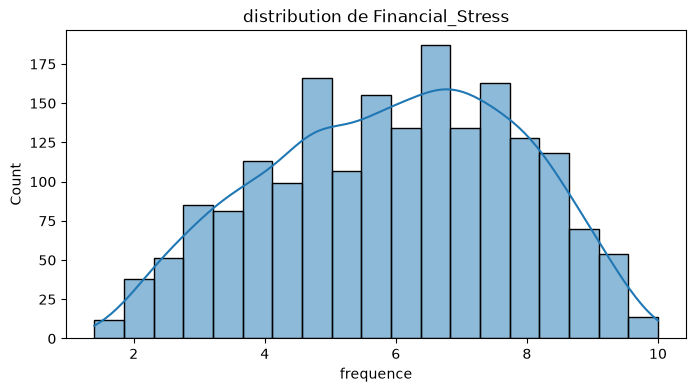

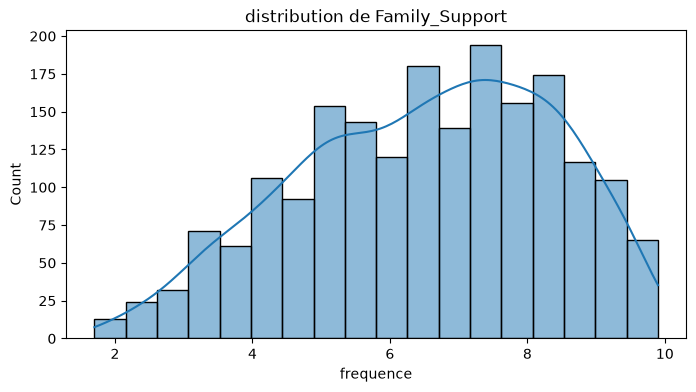

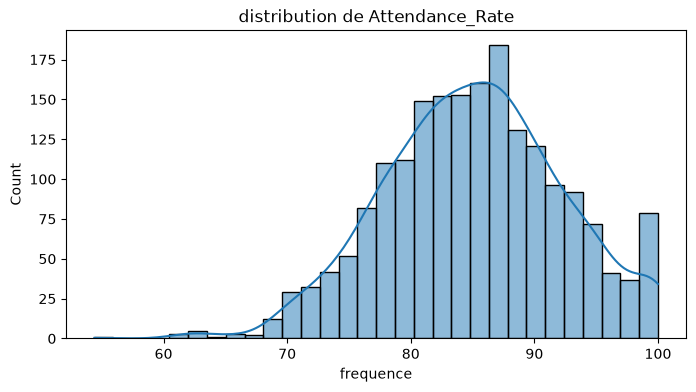

In [15]:
# print(data.columns.tolist())
for col in numeric_columns:
    plt.figure(figsize=(8,4))

    sns.histplot(data=data,x=col,kde=True)

    plt.title(f"distribution de {col}")
    plt.xlabel("frequence")

    plt.show()


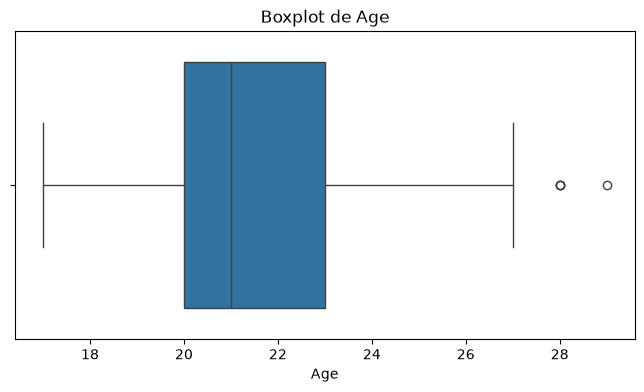

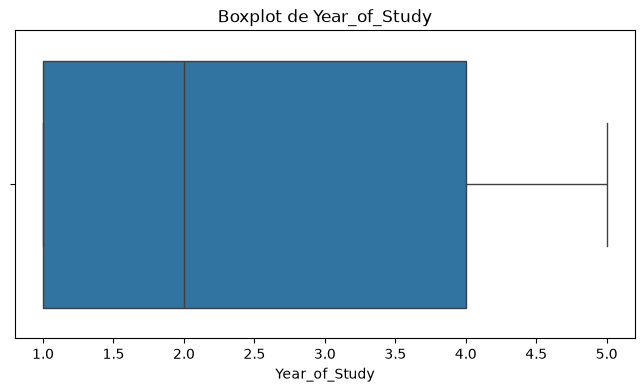

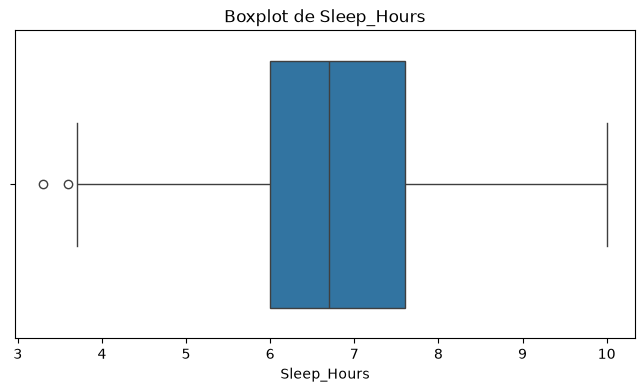

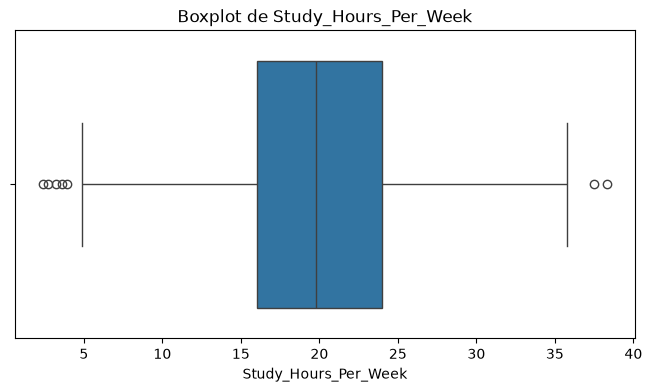

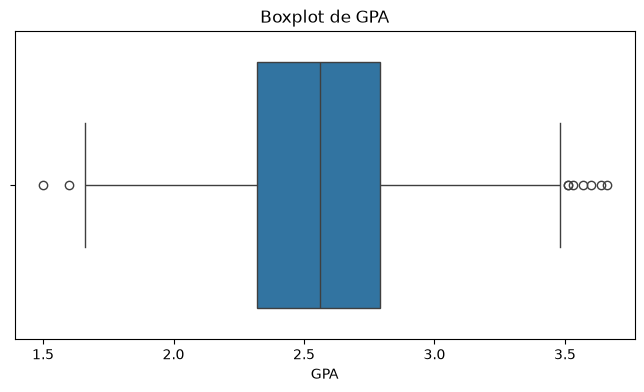

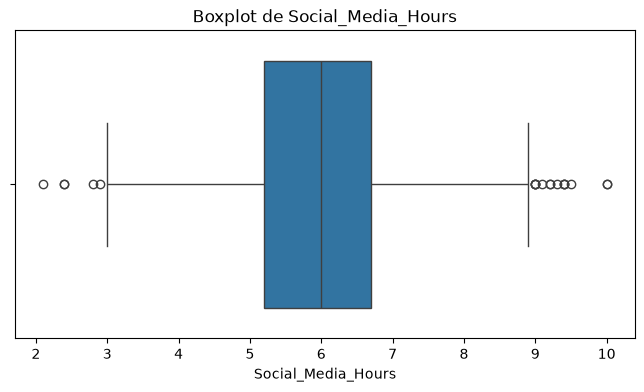

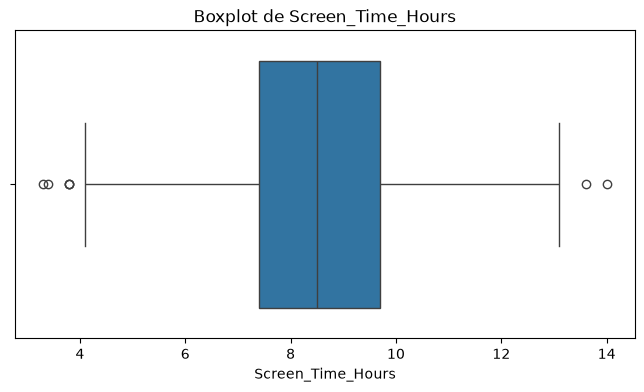

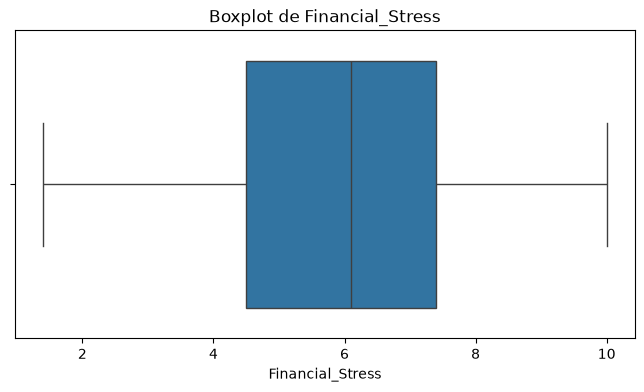

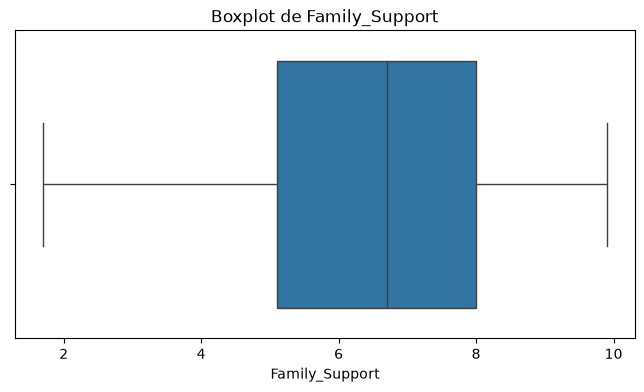

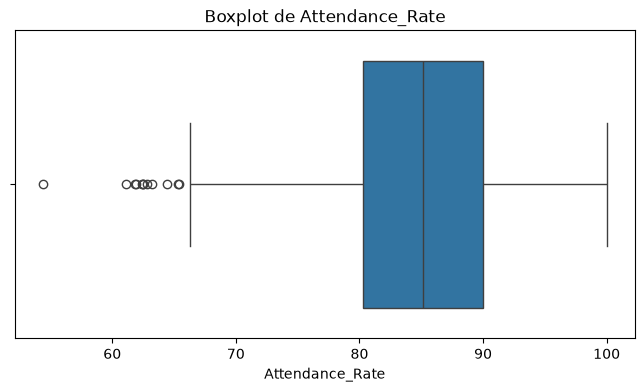

In [16]:
for col in numeric_columns:
    plt.figure(figsize=(8,4))

    sns.boxplot(x=data[col])
    plt.title(f"Boxplot de {col}")
    plt.xlabel(col)

    plt.show()




-----------Gender------------
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

 pourcentage : 
Gender
Female        48.55
Male          46.60
Non-binary     4.85
Name: proportion, dtype: float64


C:\Users\elgot\AppData\Local\Temp\ipykernel_15916\1182966136.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = data.select_dtypes(include="object").columns


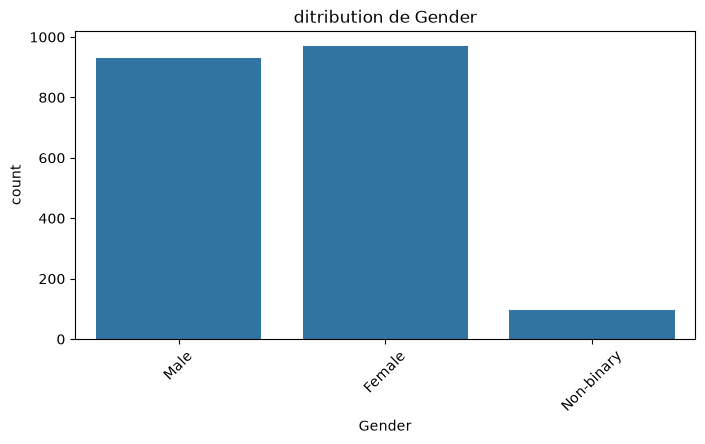


-----------Physical_Activity------------
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

 pourcentage : 
Physical_Activity
Moderate    45.30
Low         33.95
High        20.75
Name: proportion, dtype: float64


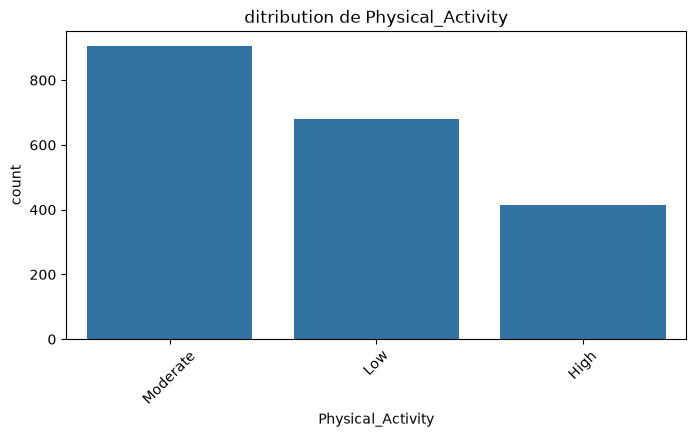


-----------Part_Time_Job------------
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

 pourcentage : 
Part_Time_Job
No     64.45
Yes    35.55
Name: proportion, dtype: float64


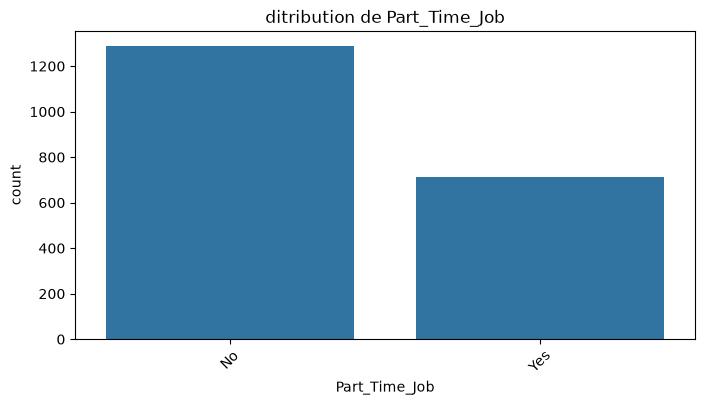


-----------Diet_Quality------------
Diet_Quality
Average    860
Poor       587
Good       484
Name: count, dtype: int64

 pourcentage : 
Diet_Quality
Average    44.536510
Poor       30.398757
Good       25.064733
Name: proportion, dtype: float64


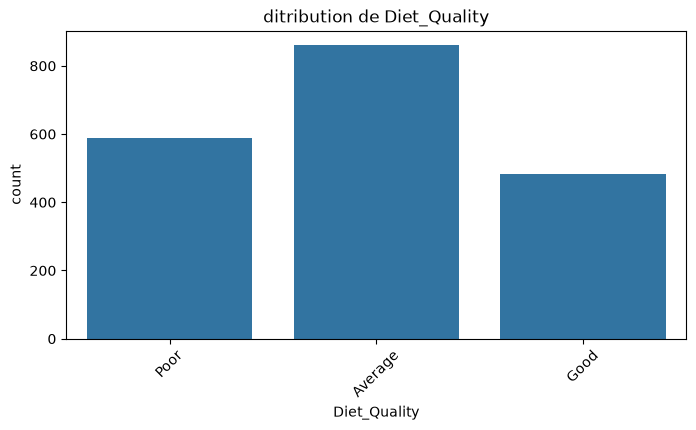


-----------Previous_Mental_Health_History------------
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

 pourcentage : 
Previous_Mental_Health_History
No     70.4
Yes    29.6
Name: proportion, dtype: float64


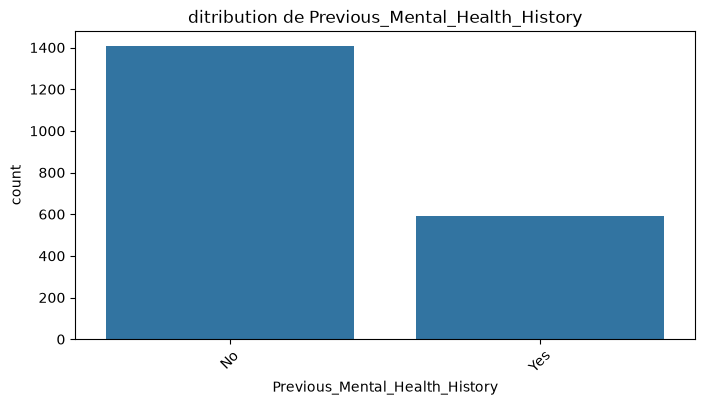


-----------Mental_Health_Risk------------
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

 pourcentage : 
Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


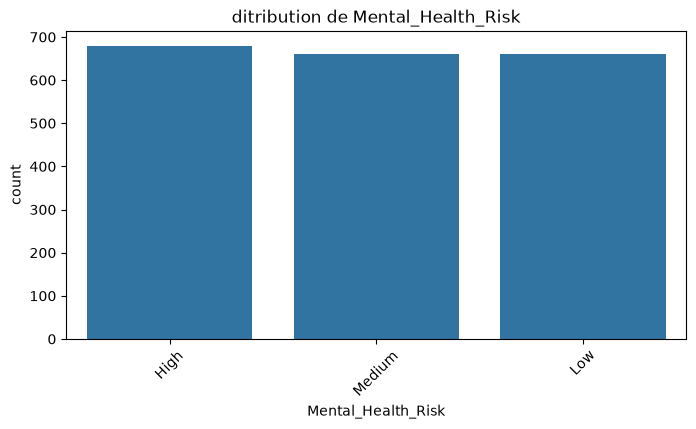

In [17]:
# les variable categorielle

categorical_columns = data.select_dtypes(include="object").columns
categorical_columns=categorical_columns.drop(
    "Student_ID",errors="ignore"
)

for col in categorical_columns:

    print(f"\n-----------{col}------------")
    print(data[col].value_counts())
    print("\n pourcentage : ")
    print(data[col].value_counts(normalize=True)*100)

    plt.figure(figsize=(8,4))
    sns.countplot(data=data,x=col)

    plt.title(f"ditribution de {col}")
    plt.xticks(rotation=45)
    plt.show()

les trois classes sont presque également représentées. Il n'existe donc pas de déséquilibre important entre les classes de la variable cible.

In [18]:
print(data.columns.tolist())

['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress', 'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']


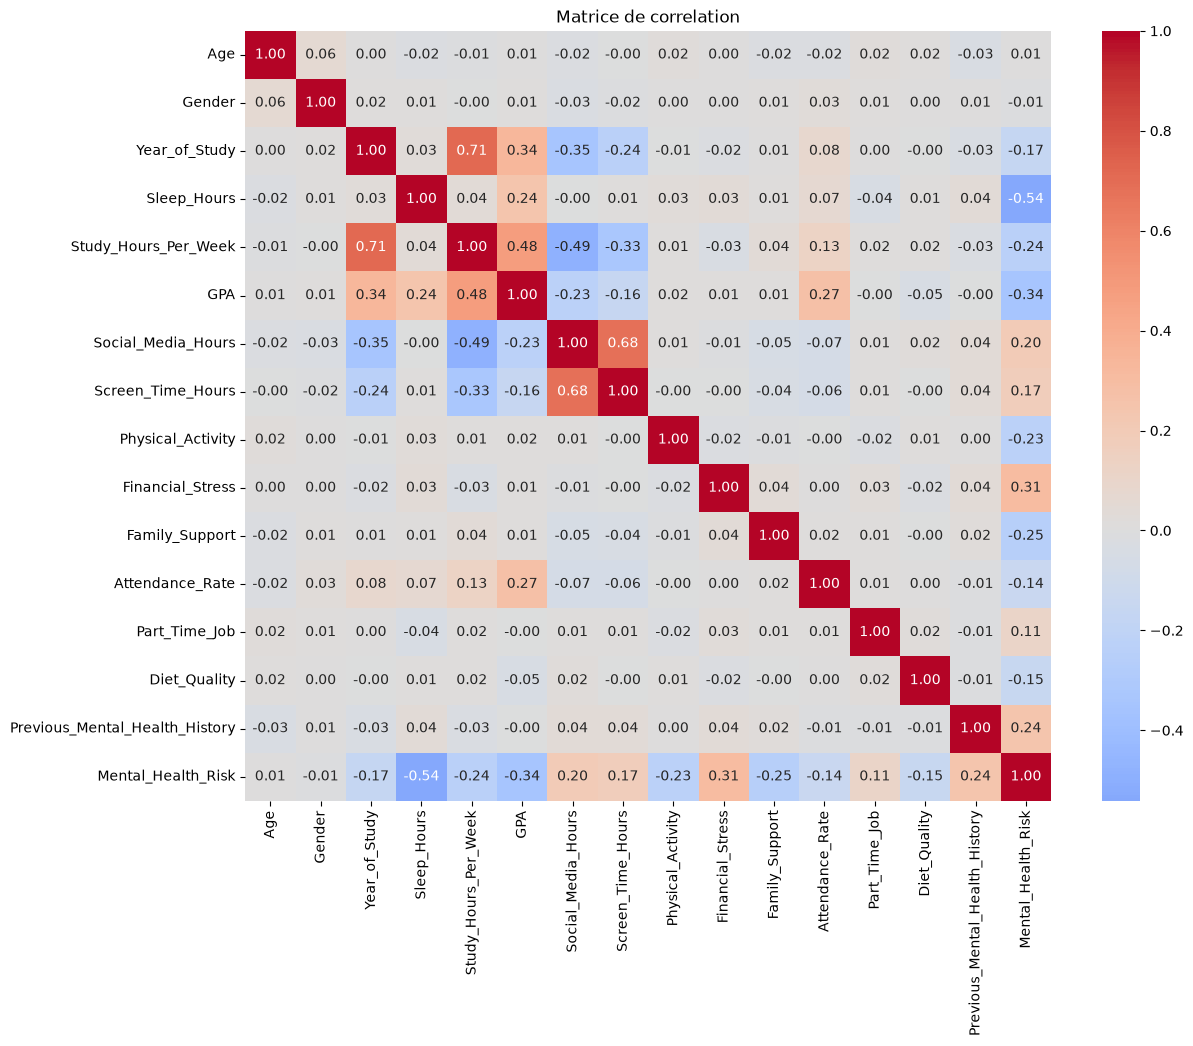

In [19]:
df_enc = data.drop(columns=["Student_ID"]).copy()

df_enc = df_enc.replace({
    "Male": 0, "Female": 1, "Non-binary": 2,
    "Low": 0, "Moderate": 1, "Medium": 1, "High": 2,
    "Poor": 0, "Average": 1, "Good": 2,
    "No": 0, "Yes": 1
})

corr_matrix = df_enc.corr(method="spearman")

plt.figure(figsize=(13, 10))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matrice de correlation")
plt.show()

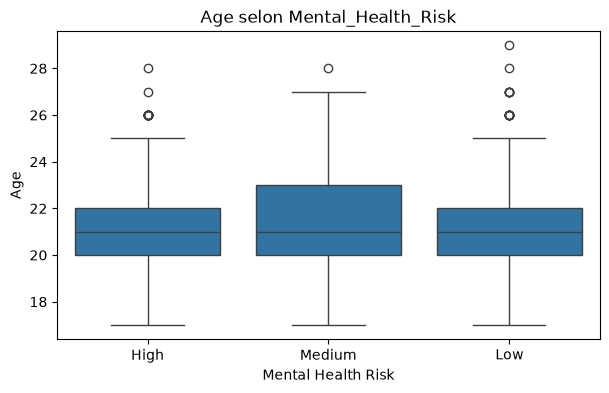

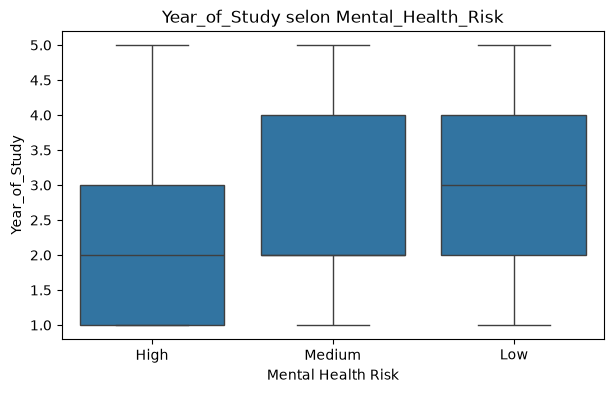

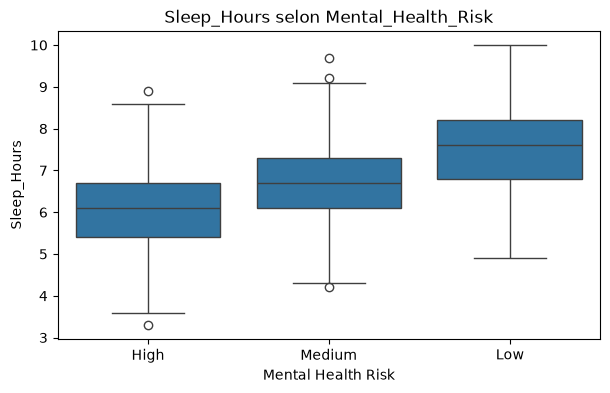

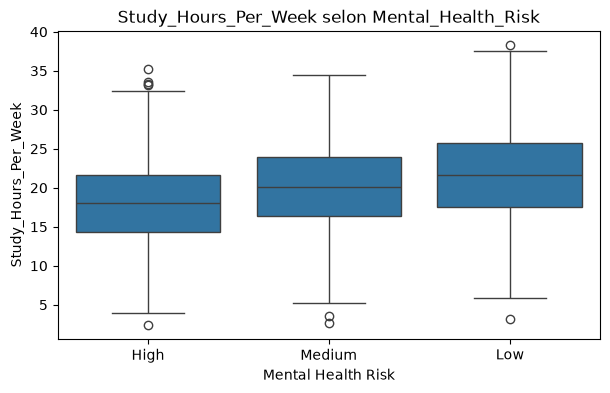

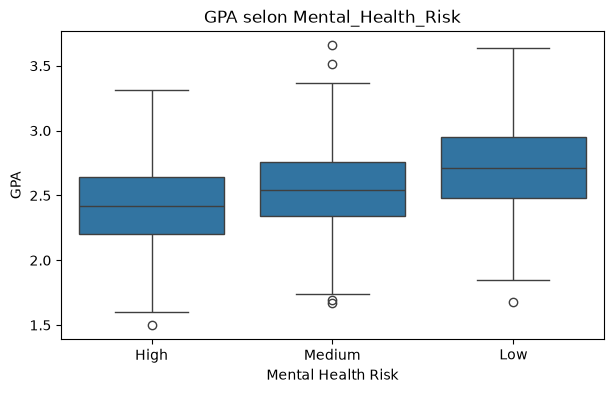

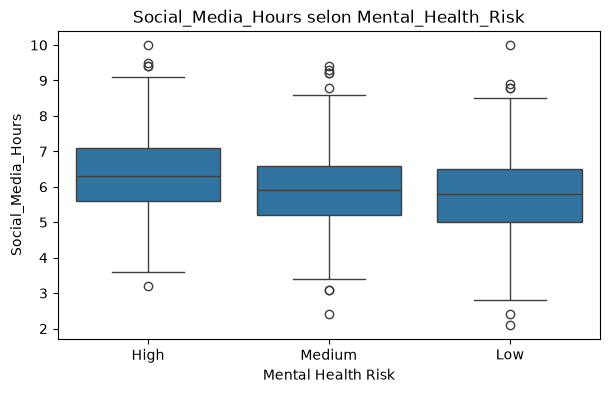

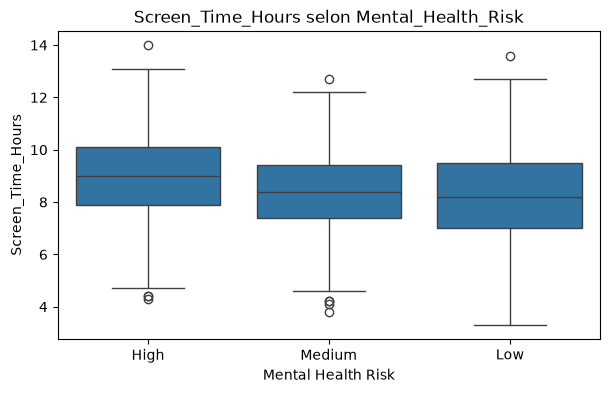

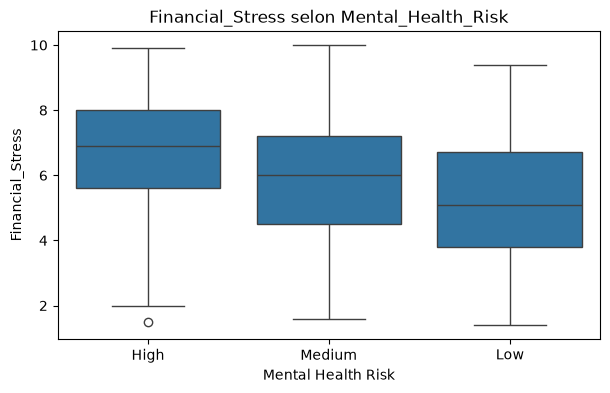

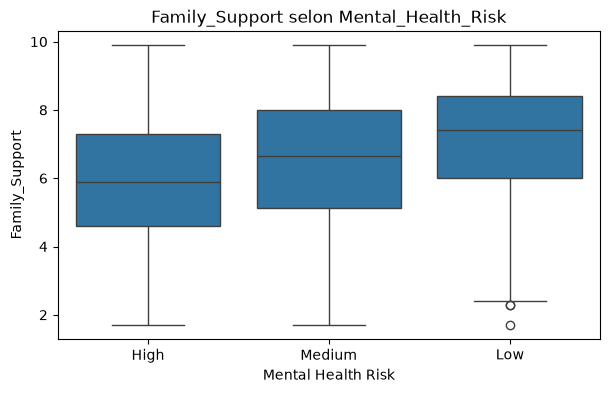

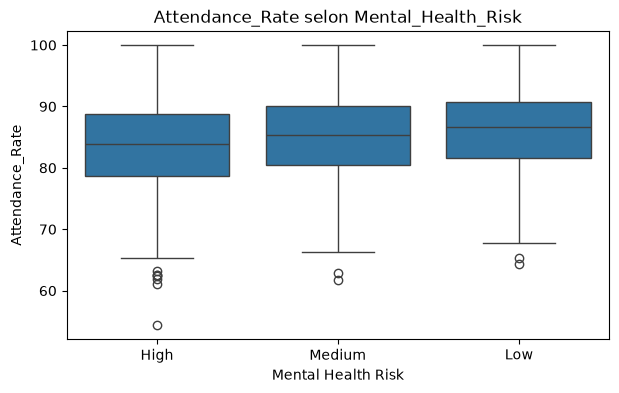

In [ ]:
#  la relation entre les variable et target
target_col = "Mental_Health_Risk"

for col in numeric_columns:
    if col != target_col:
        plt.figure(figsize=(7, 4))

        sns.boxplot(data=data, x=target_col, y=col)

        plt.title(f"{col} selon {target_col}")
        plt.xlabel("Mental Health Risk")
        plt.ylabel(col)

        plt.show()


 ---------- Gender selon Mental_Health_Risk ----------
Mental_Health_Risk   High    Low  Medium
Gender                                  
Female              34.60  33.47   31.93
Male                33.37  31.76   34.87
Non-binary          34.02  40.21   25.77


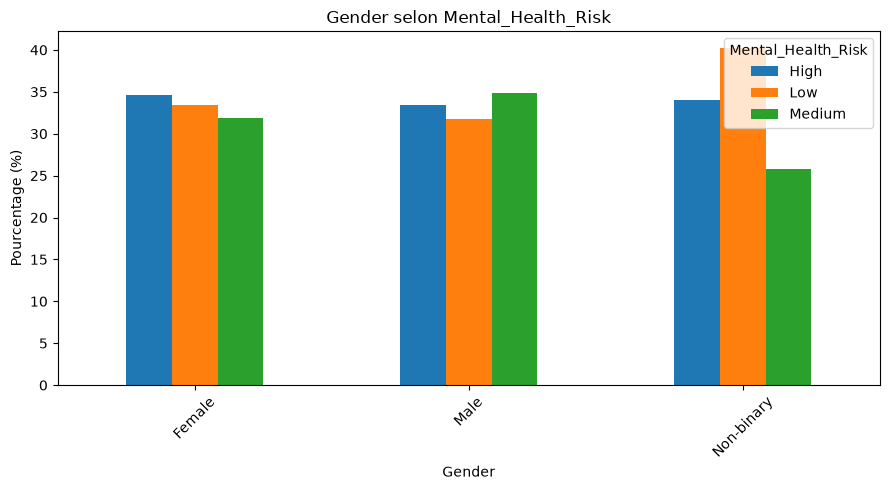


 ---------- Physical_Activity selon Mental_Health_Risk ----------
Mental_Health_Risk   High    Low  Medium
Physical_Activity                       
High                20.24  49.40   30.36
Low                 45.95  22.83   31.22
Moderate            31.35  33.11   35.54


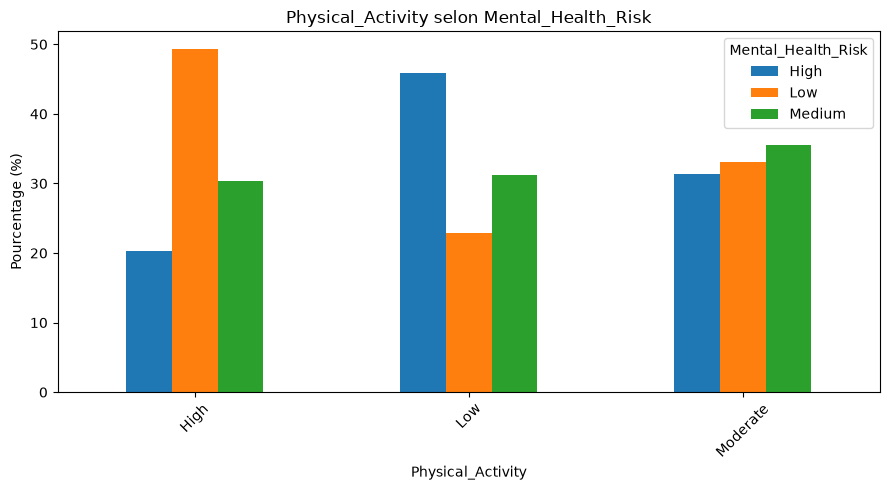


 ---------- Part_Time_Job selon Mental_Health_Risk ----------
Mental_Health_Risk   High    Low  Medium
Part_Time_Job                           
No                  30.26  36.23   33.51
Yes                 40.79  27.14   32.07


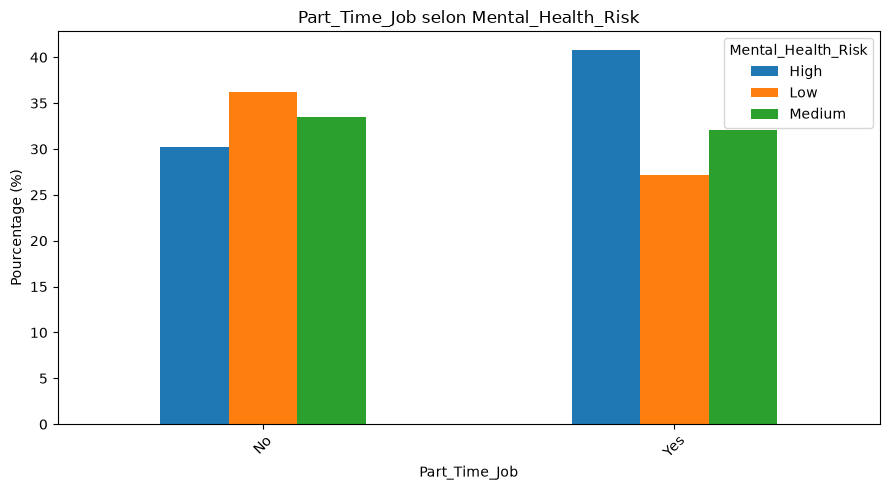


 ---------- Diet_Quality selon Mental_Health_Risk ----------
Mental_Health_Risk   High    Low  Medium
Diet_Quality                            
Average             32.33  33.49   34.19
Good                27.48  42.77   29.75
Poor                42.25  24.02   33.73


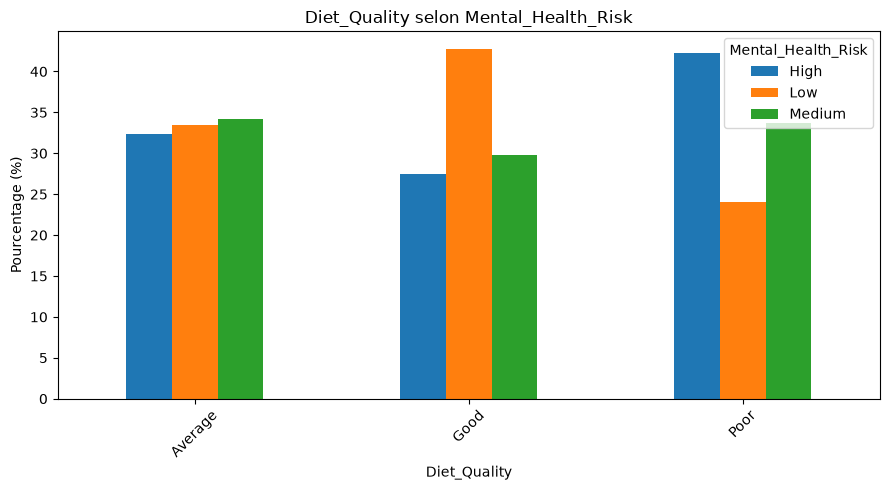


 ---------- Previous_Mental_Health_History selon Mental_Health_Risk ----------
Mental_Health_Risk               High    Low  Medium
Previous_Mental_Health_History                      
No                              27.41  39.28   33.31
Yes                             49.66  18.07   32.26


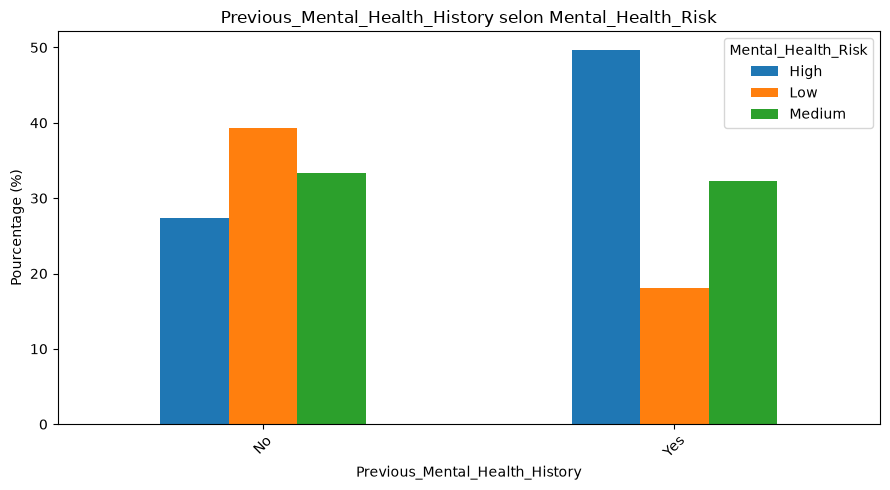

In [21]:
for col in categorical_columns:
    if col != target_col:
        print(f"\n ---------- {col} selon {target_col} ----------")

        tableau = pd.crosstab(
            data[col],
            data[target_col],
            normalize="index"
        ) * 100

        print(tableau.round(2))
        tableau.plot(kind="bar",figsize=(9,5))

        plt.title(f"{col} selon {target_col}")
        plt.ylabel("Pourcentage (%)")
        plt.xticks(rotation=45)
        plt.legend(title=target_col)
        plt.tight_layout()
        plt.show()


Les étudiants ayant une activité physique élevée sont davantage représentés dans la classe Low.

Les étudiants ayant un emploi à temps partiel présentent une proportion plus élevée de classe High que ceux sans emploi.

Une mauvaise qualité alimentaire est associée à une proportion plus élevée de classe High.

Les étudiants ayant un historique de santé mentale présentent une proportion de classe High plus importante.

In [28]:
data.to_csv("../data/student_mental_health_clean.csv", index=False)